# Fast Reproduction of Main Empirical Results
A list of the main empirical deliverables
- Tables 1, 3, and 4
- Figures 2 and 4

**⚠️ Important:** NumPy, pandas, matplotlib, and seaborn are required to run this notebook.

In [1]:
import numpy as np
import pandas as pd
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

# Formatted names of the dataset
formatted_names = {
    'ailerons': 'Ailerons',
    'bikesharing': 'Bikesharing',
    'california': 'California',
    'concrete': 'Concrete',
    'elevators': 'Elevators',
    'energy': 'Energy',
    'forestfires': 'ForestFires',
    'house': 'House',
    'NavalPropolsion': 'NavalProp',
    'puma32h': 'Puma32h',
    'SkillCraft': 'SkillCraft',
    'sml2010': 'SML2010',
    'superconductivity': 'Supercond',
    'support2': 'Support2',
    'synchronous': 'Synchronous',
    'Thermography': 'Thermography',
    'toxicity': 'Toxicity',
    'treasury': 'Treasury',
    'wizmir': "Wizmir"
}
formatted_names.update({"Average Rank": "Avg. Rank"})

# Suffix of the experiment names
names = ["_fixed_mixint", "_ratio_mixint"]

### To produce Tables 1 and 3. 
**!** This is not an exact replication of Tables 1 and 3, but rather the raw data used to generate them.

In [2]:
# Table 1 of Section 5.2 "Sufficiency: AtomSD finds deviant subgroups at every support threshold"
exp_res = {}
res_dir = "./results/Experiment3/"
for name in names:
    res_path = f"{res_dir}/Experiment3_alpha{name}/results/All_subgroups_scores.csv"
    if Path(res_path).exists():
        df = pd.read_csv(res_path)
    else:
        continue
    df2 = df.copy()
    df2[['method', 'name']] = df2['base'].str.split('-', n=1, expand=True)
    cols = ['dataset', 'cv', 'rep', 'alpha', 'name', 'method', 'KL_train', 'support_train', 'KL_test', 'support_test']
    tmp = df2[cols].copy()

    idx = tmp.groupby(
        ['dataset', 'cv', 'rep', 'alpha', 'method', 'name']
    )['KL_train'].idxmax()
    
    tmp_best = tmp.loc[idx]
    wide = tmp_best.pivot_table(
        index=['dataset', 'cv', 'rep', 'alpha', 'name'],
        columns='method',
        values=['KL_train', 'support_train', 'KL_test', 'support_test'],
        aggfunc='first'
    )
    wide.columns = [f'{v}_{m}' for v, m in wide.columns]
    wide = wide.reset_index()

    result = wide[
        ['dataset', 'cv', 'alpha', 'KL_train_cdtree',  'support_train_cdtree', 'KL_test_cdtree', 'support_test_cdtree']
    ]

    result.loc[:, 'KL_test_cdtree'] = result['KL_test_cdtree'].astype(float)
    result = result.copy()
    result.rename(columns={'KL_test_cdtree': 'KL_test'}, inplace=True)
    result.rename(columns={'support_train_cdtree': 'support_train'}, inplace=True)
    result.rename(columns={'KL_train_cdtree': 'KL_train'}, inplace=True)
    result.rename(columns={'support_test_cdtree': 'support_test'}, inplace=True)
    result.loc[:, 'method'] = "AtomSD"
    exp_res[name] = result

# Load the result of uncontrained experiment
exp1_result = pd.read_csv(f"./results/Experiment1/Experiment1.csv")
exp1_result_feasible = exp1_result[exp1_result['support_train'] >= 50]

dfs_exp3 = {}
tables = {}
for key, res in exp_res.items():
    df_exp1 = pd.DataFrame()
    df_all = pd.DataFrame()
    for alpha in res['alpha'].unique():
        if alpha <= 1:
            satisfied_exp1_subgroups = exp1_result_feasible[exp1_result_feasible['support_ratio_train'] >= alpha]
        else:
            satisfied_exp1_subgroups = exp1_result_feasible[exp1_result_feasible['support_train'] >= alpha]

        df_best = satisfied_exp1_subgroups.loc[satisfied_exp1_subgroups.groupby(['cv', 'rep', 'dataset', 'method'])['KL_train'].idxmax()]
        df_best['alpha'] = alpha
        df_best = df_best[['dataset', 'cv', 'alpha', 'method', 'KL_train', 'support_train', 'KL_test', 'support_test']]
        df_exp1 = pd.concat([df_exp1, df_best], ignore_index=True)
    df_exp1 = df_exp1[df_exp1['method'] != "AtomSD"] # There is no need to involve
    df_all = pd.concat([df_exp1, res], ignore_index=True)
    df_all.sort_values(by=['dataset', 'alpha', 'cv', 'method'], inplace=True, key=lambda col: col.str.lower() if col.name == 'dataset' else col)
    df_all['dataset'] = df_all['dataset'].map(formatted_names)
    df_all.replace({'sd_mean': r'SD$-{\mu}$', 'syflow': 'SyFlow', 'sd_kl': r'SD$-\text{KL}$', 'rsd': r'RSD'}, inplace=True)
    # df_all.sort_values(by=['dataset', 'alpha', 'cv', 'method'], inplace=True)
    df_all.reset_index(drop=True, inplace=True)
    dfs_exp3.update({key: df_all})
    df_all.to_csv(f"{res_dir}/result_exp3{key}_raw.csv", index=False)

    # If we ignore the unsatisfied subgroup entries as np.nan
    table = df_all.pivot_table(
        index=['dataset', 'alpha'],
        columns='method',
        values='KL_test',
        aggfunc=np.nanmean
    ).reset_index()
    table.columns.name = None
    tables.update({key: table})

In [3]:
from util_plot import get_statistics
table1 = get_statistics(tables[names[0]])
# table1.to_csv(f"{res_dir}/Table3_sufficiency{names[0]}.csv", index=False, float_format="%.3f")
print("Table 1: Sufficiency: AtomSD finds deviant subgroups at every support threshold")
table1

Table 1: Sufficiency: AtomSD finds deviant subgroups at every support threshold


,dataset,alpha,AtomSD,RSD,SD$-\text{KL}$,SD$-{\mu}$,SyFlow
0,Ailerons,50.0,\textbf{1.768},1.363,0.981,1.053,1.312
1,Ailerons,100.0,\textbf{1.718},1.244,0.981,1.053,1.312
2,Ailerons,150.0,\textbf{1.684},0.000,0.981,1.053,1.312
3,Ailerons,200.0,\textbf{1.475},0.000,0.981,1.053,1.312
4,Ailerons,300.0,\textbf{1.684},0.000,0.981,1.053,1.312
...,...,...,...,...,...,...,...
1,\#Best,100.0,16,1,1,0,1
2,\#Best,150.0,18,0,0,0,1
3,\#Best,200.0,18,0,0,0,1
4,\#Best,300.0,16,0,0,1,2


In [4]:
table3 = get_statistics(tables[names[1]])
# table3.to_csv(f"{res_dir}/Table3_sufficiency{names[1]}.csv", index=False, float_format="%.3f")
print("Table 3: Sufficiency: AtomSD finds deviant subgroups at every support threshold (ratio)")
table3

Table 3: Sufficiency: AtomSD finds deviant subgroups at every support threshold (ratio)


,dataset,alpha,AtomSD,RSD,SD$-\text{KL}$,SD$-{\mu}$,SyFlow
0,Ailerons,0.05,\textbf{1.491},0.000,0.981,1.053,1.312
1,Ailerons,0.10,\textbf{1.347},0.000,0.981,1.053,1.312
2,Ailerons,0.20,\textbf{1.069},0.000,0.981,1.053,1.055
3,Ailerons,0.30,1.051,0.000,0.000,1.053,\textbf{1.065}
4,Bikesharing,0.05,\textbf{2.180},0.000,1.290,0.000,0.704
...,...,...,...,...,...,...,...
0,\#Best,0.05,14,2,0,1,2
1,\#Best,0.10,14,1,1,0,3
2,\#Best,0.20,19,0,0,0,0
3,\#Best,0.30,17,0,0,0,2


### To reproduce the Table 4.
**!** This is not an exact replica of Table 4, but rather a major LaTex sketch of it.

In [5]:
### Raw results for unconstrained subgroup discovery
all_scores = pd.read_csv(f"./results/Experiment1/Experiment1.csv")
df_best = all_scores.loc[all_scores.groupby(['cv', 'rep', 'dataset', 'method'])['KL_train'].idxmax()]
df_best = df_best.replace(-np.inf, np.nan)
# df_best = df_best.replace(-np.inf, 0.0000)
df_best.sort_values(by=['dataset', 'cv', 'KL_test'], ascending=[True, True, False], inplace=True)
df_best['KL_test_mean'] = (
    df_best
    .groupby(['dataset', 'method'])['KL_test']
    .transform(np.nanmean)
)
df_best['KL_test_std'] = (
    df_best
    .groupby(['dataset', 'method'])['KL_test']
    .transform(np.nanstd)
)
df_best['KL_train_mean'] = (
    df_best
    .groupby(['dataset', 'method'])['KL_train']
    .transform(np.nanmean)
)
df_best['support_train_mean'] = (
    df_best
    .groupby(['dataset', 'method'])['support_train']
    .transform(np.nanmean)
)
df_best['support_test_mean'] = (
    df_best
    .groupby(['dataset', 'method'])['support_test']
    .transform(np.nanmean)
)
df_best.to_csv(f"./results/Experiment1/Experiment1_best_subgroups.csv", index=False)
final_result = df_best[['dataset', 'method', 
                        'KL_test_mean', 
                        'KL_test_std',
                        'support_train_mean',
                        'support_test_mean',
                        ]]
final_result = (final_result.sort_values(by=['dataset', 'method', 'KL_test_mean'], ascending=[True, True, False])
                .drop_duplicates(subset=['dataset', 'method'], keep='first'))

final_result = final_result.groupby('dataset').filter(
    lambda g: not (g['KL_test_mean'].isna().all() or g['KL_test_mean'].sum() == 0)
)

final_result['Rank'] = final_result['KL_test_mean'].groupby(final_result['dataset']).rank(ascending=False)
final_result['Rank'] = final_result['Rank'].fillna(len(final_result['method'].unique()))  # If a method has no valid subgroup, assign it the worst rank (number of methods)
final_result['Average Rank'] = final_result['Rank'].groupby(final_result['method']).transform("mean").round(3)

df_out = final_result.copy()

df_out["cell"] = (
    df_out["KL_test_mean"].map(lambda x: f"{np.round(x, 3):.3f}").replace("nan", "0.000") +
    " (" + r"$\pm$" +
    df_out["KL_test_std"].map(lambda x: f"{np.round(x, 3):.3f}").replace("nan", "0.000") +
    ")"
)

df_out["cell"] = df_out.apply(
    lambda row: rf"\textbf{{{row['cell'].split(' ')[0]}}} {row['cell'].split()[1]}" if row["Rank"] == 1 else row["cell"],
    axis=1
)

table = df_out.pivot(index="dataset", columns="method", values="cell")

# average rank per method (one value per method)
avg_rank = (
    df_out[["method", "Average Rank"]]
    .drop_duplicates("method")
    .set_index("method")
    .reindex(table.columns)["Average Rank"]
)

table.loc["Average Rank"] = avg_rank.map(lambda x: f"{x:.3f}")
table.columns.name = None

table['dataset'] = table.index
table = table[['dataset'] + [col for col in table.columns if col != 'dataset']]
table.reset_index(drop=True, inplace=True)
# table.replace("nan", "--", inplace=True)
table['dataset'] = table['dataset'].map(formatted_names)
table.iloc[:-1, :] = table.iloc[:-1, :].sort_values(by='dataset', ascending=True)
table

,dataset,cdtree,rsd,sd_kl,sd_mean,syflow
0,Ailerons,\textbf{1.446} ($\pm$0.442),1.363 ($\pm$0.168),0.981 ($\pm$0.000),1.053 ($\pm$0.005),1.312 ($\pm$0.390)
1,Bikesharing,\textbf{3.056} ($\pm$0.104),0.891 ($\pm$0.300),1.290 ($\pm$0.000),2.889 ($\pm$0.229),1.246 ($\pm$0.386)
2,California,\textbf{1.962} ($\pm$0.209),-0.694 ($\pm$0.000),0.000 ($\pm$0.000),1.316 ($\pm$0.108),0.747 ($\pm$0.072)
3,Concrete,1.147 ($\pm$0.163),1.174 ($\pm$0.201),0.000 ($\pm$0.000),\textbf{1.220} ($\pm$0.224),1.213 ($\pm$0.190)
4,Elevators,\textbf{1.509} ($\pm$0.096),0.000 ($\pm$0.000),-0.268 ($\pm$0.244),-0.100 ($\pm$0.063),0.447 ($\pm$0.209)
5,Energy,2.105 ($\pm$0.083),\textbf{2.229} ($\pm$0.138),1.088 ($\pm$0.035),1.250 ($\pm$0.020),0.844 ($\pm$0.067)
6,ForestFires,0.000 ($\pm$0.000),0.131 ($\pm$0.000),0.000 ($\pm$0.000),0.000 ($\pm$0.000),\textbf{0.579} ($\pm$0.000)
7,House,\textbf{1.697} ($\pm$0.291),0.000 ($\pm$0.000),0.000 ($\pm$0.000),1.501 ($\pm$0.107),0.447 ($\pm$0.112)
8,NavalProp,\textbf{1.687} ($\pm$0.093),1.242 ($\pm$0.283),0.878 ($\pm$0.542),0.449 ($\pm$0.582),0.952 ($\pm$0.358)
9,Puma32h,2.769 ($\pm$0.230),\textbf{3.088} ($\pm$0.292),0.574 ($\pm$0.008),1.913 ($\pm$0.068),0.439 ($\pm$0.009)


### To reproduce Figures 2 and 4

Figure 2


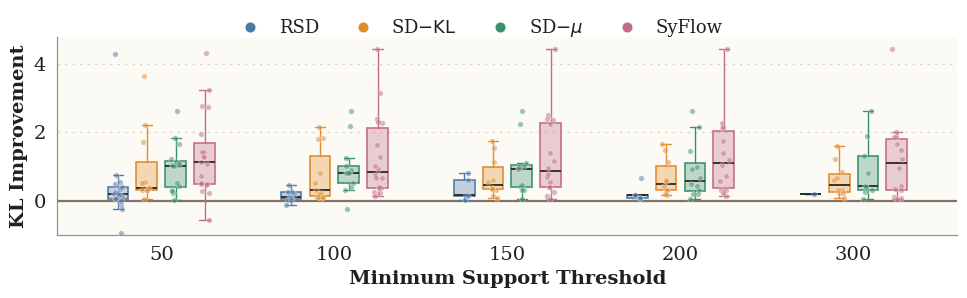

Figure 4


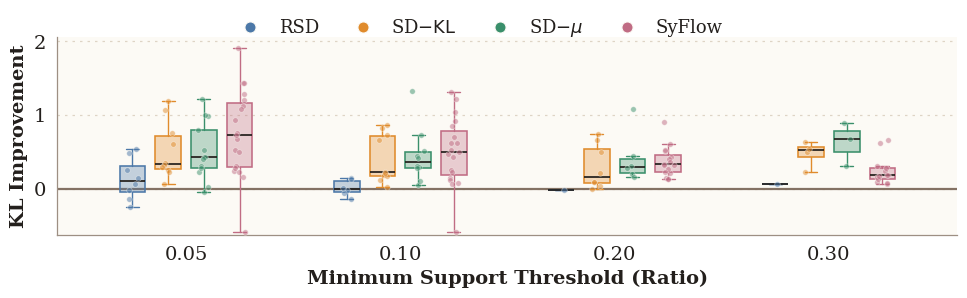

In [6]:
# Prepare the tables
res_dir = "./results/Experiment2/"
for name in names:
    res_path = f"{res_dir}/Experiment2_alpha{name}/results/All_subgroups_scores.csv"
    if Path(res_path).exists():
        df = pd.read_csv(res_path)
    else:
        continue
    df2 = df.copy()
    df2[['method', 'name']] = df2['base'].str.split('-', n=1, expand=True)

    cols = ['dataset', 'cv', 'rep', 'alpha', 'name', 'method', 'KL_test', 'satisfy_alpha']
    tmp = df2[cols].copy()

    wide = tmp.pivot_table(
        index=['dataset', 'cv', 'rep', 'alpha', 'name'],
        columns='method',
        values=['KL_test', 'satisfy_alpha'],
        aggfunc='first'
    )

    wide.columns = [f'{v}_{m}' for v, m in wide.columns]
    wide = wide.reset_index()
    wide['kl_compare'] = wide['KL_test_cdtree'] - wide['KL_test_original']
    wide['satisfy_alpha_result'] = wide['satisfy_alpha_cdtree'].fillna(False).astype(bool)
    wide['cdtree_missing_flag'] = wide['KL_test_cdtree'].isna()
    wide = wide[~wide['cdtree_missing_flag'].groupby(wide['dataset']).transform('all')]

    result = wide[
        ['dataset', 'cv', 'rep', 'alpha', 'name', 'kl_compare', 'satisfy_alpha_result', 'cdtree_missing_flag']
    ]

    result_post = result.groupby(['dataset', 'alpha', 'name'])['kl_compare'].mean()
    result_post_wide = result_post.unstack()

    metric_cols = ['rsd', 'sd_kl', 'sd_mean', 'syflow']
    result_post_wide = result_post_wide.reset_index().sort_values(by=['dataset', 'alpha'], 
                                                                  key=lambda col: col.str.lower() if col.name == 'dataset' else col)
    result_post_wide.to_csv(f'{res_dir}/result_post_wide{name}.csv', index=False)

import matplotlib.pyplot as plt
from util_plot import make_boxplot
OUTPUT_DIR = Path(res_dir)

import pandas as pd

df = pd.read_csv(f"{res_dir}/result_post_wide_fixed_mixint.csv")

publication_palette = {
    "rsd": "#4C78A8",
    "sd_kl": "#E08B2C",
    "sd_mean": "#3A8F6B",
    "syflow": "#C06C84",
}
publication_legend = {
    "rsd": "RSD",
    "sd_kl": r"SD$-\text{KL}$",
    "sd_mean": r"SD$-{\mu}$",
    "syflow": "SyFlow",
}

tick_size = 14
show_points = True

print("Figure 2")
make_boxplot(
    df,
    OUTPUT_DIR / "Figure2.pdf",
    palette=publication_palette,
    legend_names=publication_legend,
    x_label="Minimum Support Threshold",
    y_label="KL Improvement",
    tick_size=tick_size,
    show_points=show_points
)
plt.show()

df = pd.read_csv(f"{res_dir}/result_post_wide_ratio_mixint.csv")
print("Figure 4")
make_boxplot(
    df,
    OUTPUT_DIR / "Figure4.pdf",
    palette=publication_palette,
    legend_names=publication_legend,
    x_label="Minimum Support Threshold (Ratio)",
    y_label="KL Improvement",
    tick_size=tick_size,
    show_points=show_points
)
plt.show()